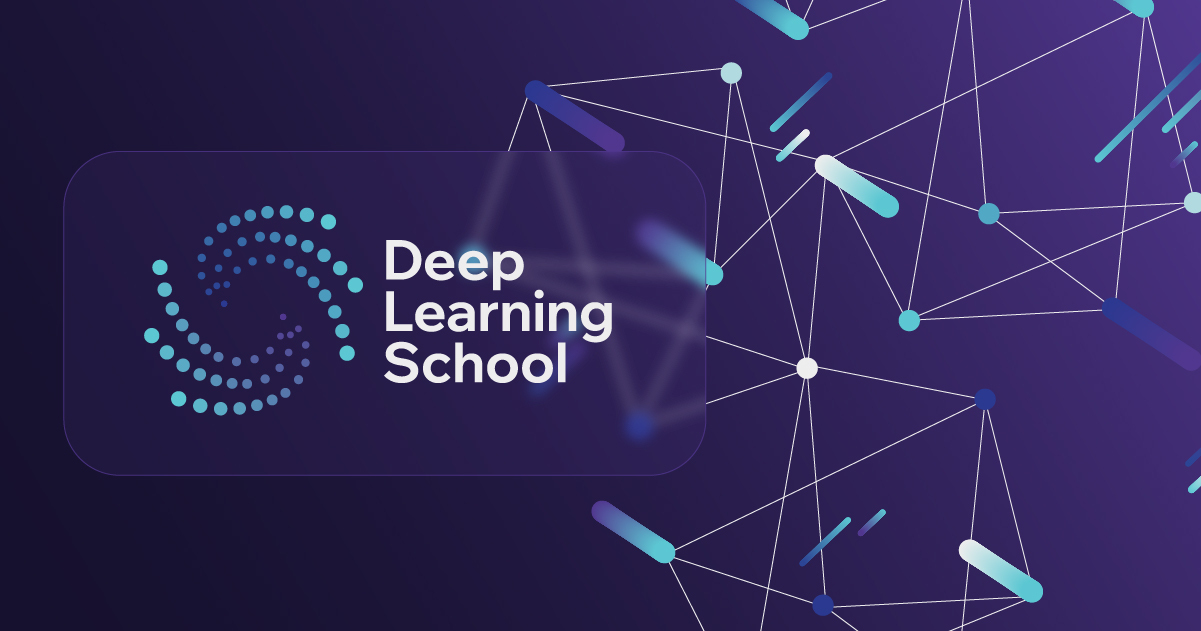

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h1 style="text-align: center;"><b>Домашнее задание. Нейросетевая классификация текстов </b></h1>

В этом домашнем задании вам предстоит самостоятельно решить задачу классификации текстов на основе семинарского кода. Мы будем использовать датасет [ag_news](https://paperswithcode.com/dataset/ag-news). Это датасет для классификации новостей на 4 темы: "World", "Sports", "Business", "Sci/Tech".

Установим модуль datasets, чтобы нам проще было работать с данными.

In [33]:
!pip install -q datasets huggingface_hub


Импорт необходимых библиотек

In [34]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import datasets

import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from datasets import load_dataset
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
import nltk

from collections import Counter
from typing import List
import string

import seaborn
seaborn.set(palette='summer')

### Персистентное хранилище весов и результатов

In [35]:
import os
import io
import torch
from huggingface_hub import HfApi, login, hf_hub_download

# --- 1. Репозиторий и подпапка на Hugging Face для этого ноутбука ---
HF_REPO_NAME = 'dls'                   # Единый репозиторий для всех ДЗ курса DLS
HF_SUBFOLDER = 'dls_part_2/weights/hw_2'   # Путь для конкретного ноутбука

# --- 2. Авторизация через HF_TOKEN из Kaggle Secrets ---
hf_token = None
try:
    from kaggle_secrets import UserSecretsClient
    user_secrets = UserSecretsClient()
    key = 'HF_TOKEN'
    hf_token = user_secrets.get_secret(key)
except Exception:
    pass

if not hf_token:
    raise RuntimeError(
        "HF_TOKEN не найден!"
    )

login(token=hf_token, add_to_git_credential=False)
api = HfApi(token=hf_token)

user_info = api.whoami()
username = user_info.get('name') or user_info.get('preferred_username')
HF_REPO_ID = f"{username}/{HF_REPO_NAME}"
api.create_repo(repo_id=HF_REPO_ID, repo_type='model', private=True, exist_ok=True)

print(f"Hugging Face подключен: https://huggingface.co/{HF_REPO_ID}")
print(f"Путь для сохранения/загрузки: {HF_SUBFOLDER}/")


Hugging Face подключен: https://huggingface.co/libertman/dls
Путь для сохранения/загрузки: dls_part_2/weights/hw_2/


In [36]:
def save_experiment(name: str, model: torch.nn.Module, losses: list, acc: list):
    """
    Сохраняет веса модели и историю обучения (losses, acc) напрямую на Hugging Face
    в подпапку dls/dls_part_2/weights/hw_2/.
    """
    print(f"Выгрузка эксперимента '{name}' на Hugging Face ({HF_REPO_ID}/{HF_SUBFOLDER})...")
    
    # 1. Сохраняем веса модели
    weights_buf = io.BytesIO()
    torch.save(model.state_dict(), weights_buf)
    weights_buf.seek(0)
    api.upload_file(
        path_or_fileobj=weights_buf,
        path_in_repo=f"{HF_SUBFOLDER}/{name}_weights.pth",
        repo_id=HF_REPO_ID,
        repo_type="model",
        commit_message=f"Save {name} weights"
    )
    
    # 2. Сохраняем результаты метрик (losses, acc)
    history_buf = io.BytesIO()
    torch.save({"losses": losses, "acc": acc}, history_buf)
    history_buf.seek(0)
    api.upload_file(
        path_or_fileobj=history_buf,
        path_in_repo=f"{HF_SUBFOLDER}/{name}_history.pt",
        repo_id=HF_REPO_ID,
        repo_type="model",
        commit_message=f"Save {name} history"
    )
    print(f"Эксперимент '{name}' успешно сохранен в Hugging Face!")


def load_experiment(name: str, model: torch.nn.Module = None, device: str = 'cpu'):
    """
    Загружает веса модели и историю метрик напрямую из Hugging Face.
    Возвращает (is_loaded, losses, acc). Если модель передана, загружает в неё веса.
    """
    weights_filename = f"{HF_SUBFOLDER}/{name}_weights.pth"
    history_filename = f"{HF_SUBFOLDER}/{name}_history.pt"
    
    try:
        weights_path = hf_hub_download(repo_id=HF_REPO_ID, filename=weights_filename, repo_type="model")
        history_path = hf_hub_download(repo_id=HF_REPO_ID, filename=history_filename, repo_type="model")
        
        if model is not None:
            model.load_state_dict(torch.load(weights_path, map_location=device))
            print(f"Веса '{name}' загружены из HF ({weights_filename})")
            
        history = torch.load(history_path, map_location="cpu")
        losses = history.get("losses", [])
        acc = history.get("acc", [])
        print(f"История '{name}' загружена ({len(losses)} эпох, лучшая accuracy: {max(acc)*100:.2f}%)")
        return True, losses, acc
    except Exception as e:
        print(f"Эксперимент '{name}' не найден на Hugging Face ({e}).")
        return False, [], []


In [37]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /usr/share/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [38]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

## Подготовка данных
Для вашего удобства, мы привели код обработки датасета в ноутбуке. Ваша задача --- обучить модель, которая получит максимальное возможное качество на тестовой части.

In [39]:
# Загрузим датасет
dataset = datasets.load_dataset('fancyzhx/ag_news')

Как и в семинаре, выполним следующие шаги:
* Составим словарь
* Создадим класс WordDataset
* Выделим обучающую и тестовую часть, создадим DataLoader-ы.

In [40]:
words = Counter()

for example in tqdm(dataset['train']['text']):
    # Приводим к нижнему регистру и убираем пунктуацию
    prccessed_text = example.lower().translate(
        str.maketrans('', '', string.punctuation))

    for word in word_tokenize(prccessed_text):
        words[word] += 1


vocab = set(['<unk>', '<bos>', '<eos>', '<pad>'])
counter_threshold = 25

for char, cnt in words.items():
    if cnt > counter_threshold:
        vocab.add(char)

# Без сортировки порядок в set зависит от случайного seed и меняется при каждом перезапуске сессии, из-за чего сохраненные веса рассинхронизируются со словарем
vocab = sorted(list(vocab))

print(f'Размер словаря: {len(vocab)}')

word2ind = {char: i for i, char in enumerate(vocab)}
ind2word = {i: char for char, i in word2ind.items()}


  0%|          | 0/120000 [00:00<?, ?it/s]

Размер словаря: 11842


### Топ 10 токенов по количеству вхождений в тексты

In [41]:
sorted(words, key=words.get, reverse=True)[:10]

['the', 'to', 'a', 'of', 'in', 'and', 'on', 'for', '39s', 'that']

In [42]:
class WordDataset:
    def __init__(self, sentences):
        self.data = sentences
        self.unk_id = word2ind['<unk>']
        self.bos_id = word2ind['<bos>']
        self.eos_id = word2ind['<eos>']
        self.pad_id = word2ind['<pad>']

    def __getitem__(self, idx: int) -> List[int]:
        processed_text = self.data[idx]['text'].lower().translate(
            str.maketrans('', '', string.punctuation))
        tokenized_sentence = [self.bos_id]
        tokenized_sentence += [
            word2ind.get(word, self.unk_id) for word in word_tokenize(processed_text)
            ]
        tokenized_sentence += [self.eos_id]

        train_sample = {
            "text": tokenized_sentence,
            "label": self.data[idx]['label']
        }

        return train_sample

    def __len__(self) -> int:
        return len(self.data)


def collate_fn_with_padding(
    input_batch: List[List[int]], pad_id=word2ind['<pad>'], max_len=256) -> torch.Tensor:
    seq_lens = [len(x['text']) for x in input_batch]
    max_seq_len = min(max(seq_lens), max_len)

    new_batch = []
    for sequence in input_batch:
        sequence['text'] = sequence['text'][:max_seq_len]
        for _ in range(max_seq_len - len(sequence['text'])):
            sequence['text'].append(pad_id)

        new_batch.append(sequence['text'])

    sequences = torch.LongTensor(new_batch).to(device)
    labels = torch.LongTensor([x['label'] for x in input_batch]).to(device)

    new_batch = {
        'input_ids': sequences,
        'label': labels
    }

    return new_batch

In [43]:
train_dataset = WordDataset(dataset['train'])

np.random.seed(42)
idx = np.random.choice(np.arange(len(dataset['test'])), 5000)
eval_dataset = WordDataset(dataset['test'].select(idx))

batch_size = 32
train_dataloader = DataLoader(
    train_dataset, shuffle=True, collate_fn=collate_fn_with_padding, batch_size=batch_size)

eval_dataloader = DataLoader(
    eval_dataset, shuffle=False, collate_fn=collate_fn_with_padding, batch_size=batch_size)

## Постановка задачи
Ваша задача -- получить максимальное возможное accuracy на `eval_dataloader`. Ниже приведена функция, которую вам необходимо запустить для обученной модели, чтобы вычислить качество её работы.

In [44]:
def evaluate(model, eval_dataloader) -> float:
    """
    Calculate accuracy on validation dataloader.
    """

    predictions = []
    target = []
    with torch.no_grad():
        for batch in eval_dataloader:
            logits = model(batch['input_ids'])
            predictions.append(logits.argmax(dim=1))
            target.append(batch['label'])

    predictions = torch.cat(predictions)
    target = torch.cat(target)
    accuracy = (predictions == target).float().mean().item()

    return accuracy

## Ход работы
Оценка за домашнее задание складывается из четырех частей:
### Запуск базовой модели с семинара на новом датасете (1 балл)
На семинаре мы создали модель, которая дает на нашей задаче довольно высокое качество. Ваша цель --- обучить ее и вычислить `score`, который затем можно будет использовать в качестве бейзлайна.

В модели появится одно важное изменение: количество классов теперь равно не 2, а 4. Обратите на это внимание и найдите, что в коде создания модели нужно модифицировать, чтобы учесть это различие.

### Проведение экспериментов по улучшению модели (2 балла за каждый эксперимент)
Чтобы улучшить качество базовой модели, можно попробовать различные идеи экспериментов. Каждый выполненный эксперимент будет оцениваться в 2 балла. Для получения полного балла за этот пункт вам необходимо выполнить по крайней мере 2 эксперимента. Не расстраивайтесь, если какой-то эксперимент не дал вам прироста к качеству: он все равно зачтется, если выполнен корректно.

Вот несколько идей экспериментов:
* **Модель RNN**. Попробуйте другие нейросетевые модели --- LSTM и GRU. Мы советуем обратить внимание на [GRU](https://pytorch.org/docs/stable/generated/torch.nn.GRU.html), так как интерфейс этого класса ничем не отличается от обычной Vanilla RNN, которую мы использовали на семинаре.
* **Увеличение количества рекуррентных слоев модели**. Это можно сделать с помощью параметра `num_layers` в классе `nn.RNN`. В такой модели выходы первой RNN передаются в качестве входов второй RNN и так далее.
* **Изменение архитектуры после применения RNN**. В базовой модели используется агрегация со всех эмбеддингов. Возможно, вы захотите конкатенировать результат агрегации и эмбеддинг с последнего токена.
* **Подбор гиперпараметров и обучение до сходимости**. Возможно, для получения более высокого качества просто необходимо увеличить количество эпох обучения нейросети, а также попробовать различные гиперпараметры: размер словаря, `dropout_rate`, `hidden_dim`.

Обратите внимание, что главное правило проведения экспериментов --- необходимо совершать одно архитектурное изменение в одном эксперименте. Если вы совершите несколько изменений, то будет неясно, какое именно из изменений дало прирост к качеству.

### Получение высокого качества (3 балла)
В конце вашей работы вы должны указать, какая из моделей дала лучший результат, и вывести качество, которое дает лучшая модель, с помощью функции `evaluate`. Ваша модель будет оцениваться по метрике `accuracy` следующим образом:
* $accuracy < 0.9$ --- 0 баллов;
* $0.9 \leqslant accuracy < 0.91$ --- 1 балл;
* $0.91 \leqslant accuracy < 0.915$ --- 2 балла;
* $0.915 \leqslant accuracy$ --- 3 балла.

### Оформление отчета (2 балла)
В конце работы подробно опишите все проведенные эксперименты.
* Укажите, какие из экспериментов принесли улучшение, а какие --- нет.
* Проанализируйте графики сходимости моделей в проведенных экспериментах. Являются ли колебания качества обученных моделей существенными в зависимости от эпохи обучения, или же сходимость стабильная?
* Укажите, какая модель получилась оптимальной.

Желаем удачи!

## Модель с семинара

In [45]:
class CharLM(nn.Module):
    def __init__(
        self, hidden_dim: int, vocab_size: int, num_classes: int = 4,
        aggregation_type: str = 'max'
        ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.RNN(hidden_dim, hidden_dim, batch_first=True)
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, num_classes)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

        self.aggregation_type = aggregation_type

    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)  # [batch_size, seq_len, hidden_dim]
        output, _ = self.rnn(embeddings)  # [batch_size, seq_len, hidden_dim]

        if self.aggregation_type == 'max':
            output = output.max(dim=1)[0] #[batch_size, hidden_dim]
        elif self.aggregation_type == 'mean':
            output = output.mean(dim=1) #[batch_size, hidden_dim]
        else:
            raise ValueError("Invalid aggregation_type")

        output = self.dropout(self.linear(self.non_lin(output)))  # [batch_size, hidden_dim]
        prediction = self.projection(self.non_lin(output))  # [batch_size, num_classes]

        return prediction

In [46]:
model = CharLM(hidden_dim=256, vocab_size=len(vocab)).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(model.parameters())

In [47]:
num_epoch = 5
eval_steps = len(train_dataloader) // 2

losses_type = {}
acc_type = {}

FORCE_RETRAIN_RNN = False

for aggregation_type in ['max', 'mean']:
    exp_name = f'rnn_{aggregation_type}'
    print(f"=== Starting for {aggregation_type} ===")

    model = CharLM(
        hidden_dim=256, vocab_size=len(vocab), aggregation_type=aggregation_type
    ).to(device)

    is_loaded, losses, acc = load_experiment(exp_name, model=model, device=device)

    if is_loaded and not FORCE_RETRAIN_RNN:
        print(f"Эксперимент {exp_name} найден на Hugging Face. Пропускаем обучение.")
    else:
        print(f"Обучаем RNN ({aggregation_type})...")
        criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
        optimizer = torch.optim.Adam(model.parameters())
        losses = []
        acc = []

        for epoch in range(num_epoch):
            epoch_losses = []
            model.train()
            for i, batch in enumerate(tqdm(train_dataloader, desc=f'Training epoch {epoch}:')):
                optimizer.zero_grad()
                logits = model(batch['input_ids'])
                loss = criterion(logits, batch['label'])
                loss.backward()
                optimizer.step()

                epoch_losses.append(loss.item())
                if i % eval_steps == 0:
                    model.eval()
                    acc.append(evaluate(model, eval_dataloader))
                    model.train()

            losses.append(sum(epoch_losses) / len(epoch_losses))

        save_experiment(exp_name, model, losses, acc)

    losses_type[aggregation_type] = losses
    acc_type[aggregation_type] = acc


=== Starting for max ===
Веса 'rnn_max' загружены из HF (dls_part_2/weights/hw_2/rnn_max_weights.pth)
История 'rnn_max' загружена (5 эпох, лучшая accuracy: 90.18%)
Эксперимент rnn_max найден на Hugging Face. Пропускаем обучение.
=== Starting for mean ===
Веса 'rnn_mean' загружены из HF (dls_part_2/weights/hw_2/rnn_mean_weights.pth)
История 'rnn_mean' загружена (5 эпох, лучшая accuracy: 90.48%)
Эксперимент rnn_mean найден на Hugging Face. Пропускаем обучение.


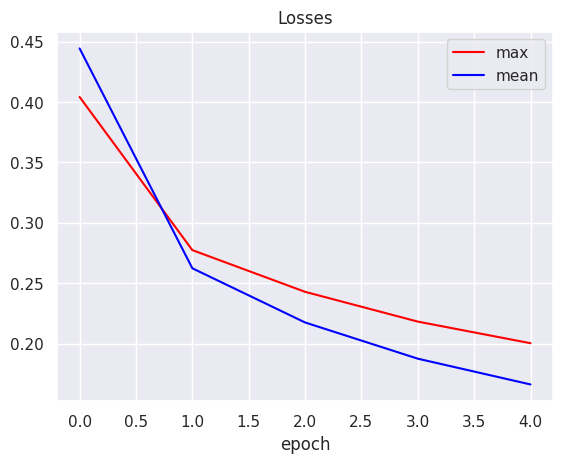

In [48]:
for (name, values), color in zip(losses_type.items(), ['red', 'blue']):
    plt.plot(np.arange(len(losses_type[name])), losses_type[name], color=color, label=name)

plt.title('Losses')
plt.xlabel("epoch")
plt.legend()
plt.show()

Лучшая accuracy для подхода max: 90.18
Лучшая accuracy для подхода mean: 90.48


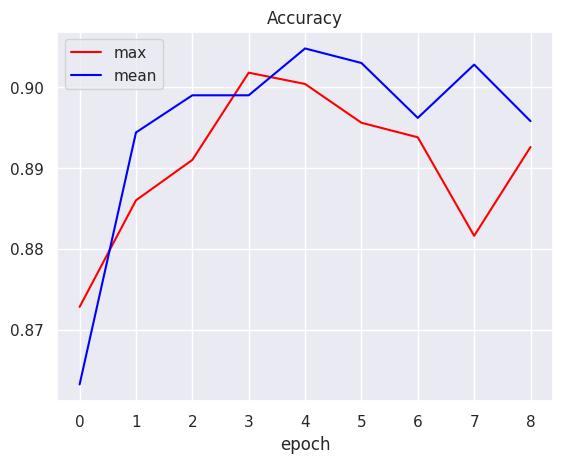

In [49]:
for (name, values), color in zip(losses_type.items(), ['red', 'blue']):
    plt.plot(np.arange(len(acc_type[name][1:])), acc_type[name][1:], color=color, label=name)
    print(f"Лучшая accuracy для подхода {name}: {(max(acc_type[name]) * 100):.2f}")

plt.title('Accuracy')
plt.xlabel("epoch")
plt.legend()
plt.show()

In [50]:
def train_model(
    model: nn.Module,
    optimizer: torch.optim.Optimizer,
    criterion: nn.Module,
    train_dataloader: DataLoader,
    eval_dataloader: DataLoader,
    num_epoch: int = 5,
    eval_steps: int = None
):
    if eval_steps is None:
        eval_steps = len(train_dataloader) // 2

    losses = []
    acc = []

    for epoch in range(num_epoch):
        epoch_losses = []
        model.train()
        for i, batch in enumerate(tqdm(train_dataloader, desc=f'Training epoch {epoch}:')):
            optimizer.zero_grad()
            logits = model(batch['input_ids'])
            loss = criterion(logits, batch['label'])
            loss.backward()
            optimizer.step()

            epoch_losses.append(loss.item())
            if i % eval_steps == 0:
                model.eval()
                acc.append(evaluate(model, eval_dataloader))
                model.train()

        losses.append(sum(epoch_losses) / len(epoch_losses))

    return losses, acc

### Эксперимент 1. Замена Vanilla RNN на LSTM

У базовой RNN скрытое состояние h_t на каждом шаге полностью перезаписывается через нелинейное преобразование. Из-за этого при бэкпропе градиенты затухают и сеть быстро теряет зависимость от токенов, которые расположены дальше какого-то числа шагов.

Однако в LSTM вводится отдельное состояние ячейки, которое служит долговременным каналом памяти. То есть градиент проходит сквозь временные шаги без затухания, позволяя модели помнить ключевые смысловые слова  от начала предложения до конца. И я надеюсь сохранение контекста поможет повысить результаты эксперимента.

In [51]:
class LSTMModel(nn.Module):
    def __init__(
        self, hidden_dim: int, vocab_size: int, num_classes: int = 4,
        aggregation_type: str = 'max'
    ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.lstm = nn.LSTM(hidden_dim, hidden_dim, batch_first=True) # внес изменения только здесь по сравнению с ваниллой
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, num_classes)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)
        self.aggregation_type = aggregation_type

    def forward(self, input_batch: torch.Tensor) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, (hidden, cell) = self.lstm(embeddings)

        if self.aggregation_type == 'max':
            output = output.max(dim=1)[0]
        elif self.aggregation_type == 'mean':
            output = output.mean(dim=1)
        else:
            raise ValueError("Invalid aggregation_type")

        output = self.dropout(self.linear(self.non_lin(output)))
        prediction = self.projection(self.non_lin(output))

        return prediction

In [ ]:
exp_name_lstm = 'lstm_max'
FORCE_RETRAIN_LSTM = False

model_lstm = LSTMModel(
    hidden_dim=256, vocab_size=len(vocab), aggregation_type='max'
).to(device)

is_loaded, lstm_losses, lstm_acc = load_experiment(exp_name_lstm, model=model_lstm, device=device)

if is_loaded and not FORCE_RETRAIN_LSTM:
    print(f"Эксперимент {exp_name_lstm} загружен из Hugging Face. Пропускаем обучение.")
    if lstm_acc:
        print(f"Лучшая accuracy из истории (LSTM Max): {(max(lstm_acc) * 100):.2f}%")
    else:
        model_lstm.eval()
        val_acc_lstm = evaluate(model_lstm, eval_dataloader)
        lstm_acc = [val_acc_lstm]
        print(f"Accuracy на валидации (LSTM Max): {(val_acc_lstm * 100):.2f}%")
else:
    print("Обучаем модель LSTM (max pooling)...")
    criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
    optimizer = torch.optim.Adam(model_lstm.parameters())

    lstm_losses, lstm_acc = train_model(
        model=model_lstm,
        optimizer=optimizer,
        criterion=criterion,
        train_dataloader=train_dataloader,
        eval_dataloader=eval_dataloader,
        num_epoch=5
    )

    save_experiment(exp_name_lstm, model_lstm, lstm_losses, lstm_acc)

    model_lstm.eval()
    val_acc_lstm = evaluate(model_lstm, eval_dataloader)
    print(f"Итоговая accuracy на валидации (LSTM Max): {(val_acc_lstm * 100):.2f}%")

Веса 'lstm_max' загружены из HF (dls_part_2/weights/hw_2/lstm_max_weights.pth)
История 'lstm_max' загружена (5 эпох, лучшая accuracy: 91.46%)
Обучаем модель LSTM (max pooling)...


Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 4::   0%|          | 0/3750 [00:00<?, ?it/s]

Uploading files as a binary IO buffer is not supported by Xet Storage. Falling back to HTTP upload.


Выгрузка эксперимента 'lstm_max' на Hugging Face (libertman/dls/dls_part_2/weights/hw_2)...


Uploading files as a binary IO buffer is not supported by Xet Storage. Falling back to HTTP upload.


Эксперимент 'lstm_max' успешно сохранен в Hugging Face!
Итоговая accuracy на валидации (LSTM Max): 89.18%


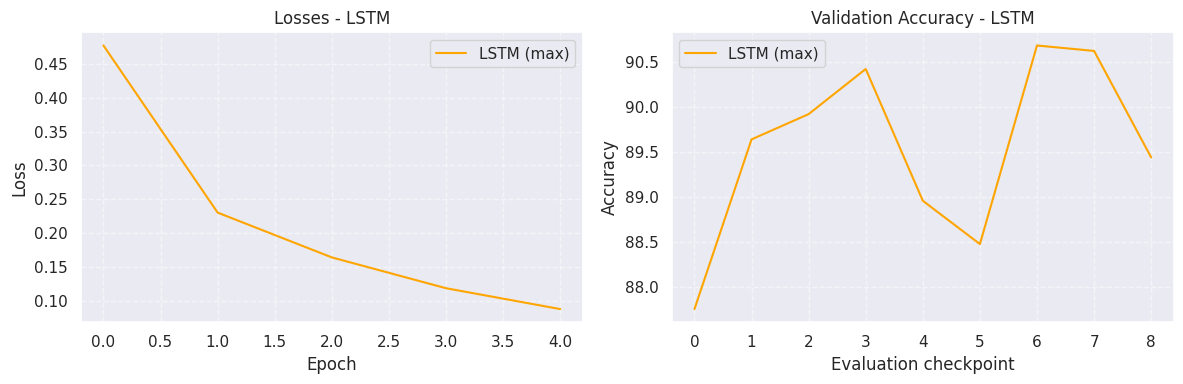

Лучшая accuracy для подхода LSTM (max): 90.68%


In [53]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(np.arange(len(lstm_losses)), lstm_losses, color='orange', label='LSTM (max)')
plt.title('Losses - LSTM')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1, 2, 2)
acc_vals = lstm_acc[1:] if len(lstm_acc) > 1 else lstm_acc
plt.plot(np.arange(len(acc_vals)), [a * 100 for a in acc_vals], color='orange', label='LSTM (max)')
plt.title('Validation Accuracy - LSTM')
plt.xlabel('Evaluation checkpoint')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

if lstm_acc:
    print(f"Лучшая accuracy для подхода LSTM (max): {(max(lstm_acc) * 100):.2f}%")

### Эксперимент 2. Двунаправленная LSTM

Классификация статьи это прежде всего анализ завершённого текста, а не посимвольная генерация речи. Однонаправленная LSTM читает текст строго слева направо, из-за чего вектор скрытого состояния для каждого слова опирается исключительно на левый предшествующий контекст. Однако в языке значение слова фундаментально зависит от слов, стоящих как слева, так и справа. Это скорее дополнение к прошлому эксперименту, т.к. про двунаправленность в маркдауне не написано было, хотя вполне логичная реализация.

Запускается два независимых рекуррентных слоя: прямой и обратный. А выход каждого шага представляет собой конкатенацию скрытых состояний $h_t = [h_t^{forward}; h_t^{backward}]$.

In [54]:
class BiLSTMModel(nn.Module):
    def __init__(
        self, hidden_dim: int, vocab_size: int, num_classes: int = 4,
        aggregation_type: str = 'max'
    ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.lstm = nn.LSTM(hidden_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.linear = nn.Linear(hidden_dim * 2, hidden_dim)
        self.projection = nn.Linear(hidden_dim, num_classes)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)
        self.aggregation_type = aggregation_type

    def forward(self, input_batch: torch.Tensor) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, (hidden, cell) = self.lstm(embeddings)

        if self.aggregation_type == 'max':
            output = output.max(dim=1)[0]
        elif self.aggregation_type == 'mean':
            output = output.mean(dim=1)
        else:
            raise ValueError("Invalid aggregation_type")

        output = self.dropout(self.linear(self.non_lin(output)))
        prediction = self.projection(self.non_lin(output))

        return prediction

In [ ]:
exp_name_bilstm = 'bilstm_max'
FORCE_RETRAIN_BILSTM = False

model_bilstm = BiLSTMModel(
    hidden_dim=256, vocab_size=len(vocab), aggregation_type='max'
).to(device)

is_loaded, bilstm_losses, bilstm_acc = load_experiment(exp_name_bilstm, model=model_bilstm, device=device)

if is_loaded and not FORCE_RETRAIN_BILSTM:
    print(f"Эксперимент {exp_name_bilstm} загружен из Hugging Face. Пропускаем обучение.")
    if bilstm_acc:
        print(f"Лучшая accuracy из истории (Bi-LSTM Max): {(max(bilstm_acc) * 100):.2f}%")
    else:
        model_bilstm.eval()
        val_acc_bilstm = evaluate(model_bilstm, eval_dataloader)
        bilstm_acc = [val_acc_bilstm]
        print(f"Accuracy на валидации (Bi-LSTM Max): {(val_acc_bilstm * 100):.2f}%")
else:
    print("Обучаем модель Bi-LSTM (max pooling)...")
    criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
    optimizer = torch.optim.Adam(model_bilstm.parameters())

    bilstm_losses, bilstm_acc = train_model(
        model=model_bilstm,
        optimizer=optimizer,
        criterion=criterion,
        train_dataloader=train_dataloader,
        eval_dataloader=eval_dataloader,
        num_epoch=5
    )

    save_experiment(exp_name_bilstm, model_bilstm, bilstm_losses, bilstm_acc)

    model_bilstm.eval()
    val_acc_bilstm = evaluate(model_bilstm, eval_dataloader)
    print(f"Итоговая accuracy на валидации (Bi-LSTM Max): {(val_acc_bilstm * 100):.2f}%")

dls_part_2/weights/hw_2/bilstm_max_weigh(…): reconstructing file:   0%|          |  0.00B / 16.9MB            

dls_part_2/weights/hw_2/bilstm_max_weigh(…): downloading bytes:           |  0.00B            

dls_part_2/weights/hw_2/bilstm_max_histo(…): reconstructing file:   0%|          |  0.00B / 1.39kB            

dls_part_2/weights/hw_2/bilstm_max_histo(…): downloading bytes:           |  0.00B            

Веса 'bilstm_max' загружены из HF (dls_part_2/weights/hw_2/bilstm_max_weights.pth)
История 'bilstm_max' загружена (5 эпох, лучшая accuracy: 90.26%)
Обучаем модель Bi-LSTM (max pooling)...


Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

... (4 outputs left out)

Uploading files as a binary IO buffer is not supported by Xet Storage. Falling back to HTTP upload.


Выгрузка эксперимента 'bilstm_max' на Hugging Face (libertman/dls/dls_part_2/weights/hw_2)...


Uploading files as a binary IO buffer is not supported by Xet Storage. Falling back to HTTP upload.


Эксперимент 'bilstm_max' успешно сохранен в Hugging Face!
Итоговая accuracy на валидации (Bi-LSTM Max): 90.02%


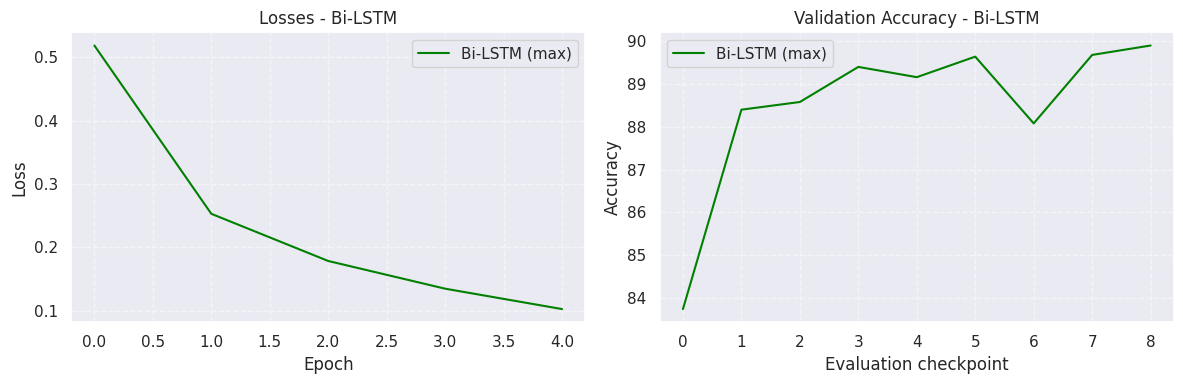

Лучшая accuracy для подхода Bi-LSTM (max): 89.90%


In [56]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(np.arange(len(bilstm_losses)), bilstm_losses, color='green', label='Bi-LSTM (max)')
plt.title('Losses - Bi-LSTM')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1, 2, 2)
acc_vals = bilstm_acc[1:] if len(bilstm_acc) > 1 else bilstm_acc
plt.plot(np.arange(len(acc_vals)), [a * 100 for a in acc_vals], color='green', label='Bi-LSTM (max)')
plt.title('Validation Accuracy - Bi-LSTM')
plt.xlabel('Evaluation checkpoint')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

if bilstm_acc:
    print(f"Лучшая accuracy для подхода Bi-LSTM (max): {(max(bilstm_acc) * 100):.2f}%")

### Эксперимент 3. Двухслойная Bi-LSTM с Dropout между слоями

В однослойной рекуррентной сети выходы вынуждены одновременно кодировать и низкоуровневые синтаксические конструкцию, а также глобальную семантическую тему документа. Второй слой же оперирует контекстуализированными эмбеддингами первого слоя, выстраивая высокоуровневые абстрактные концепции для классификации темы новости.

Также я добавил сразу же регуляризацию дропаутом, т.к. увеличение глубины модели повышает риск переобучения.

In [57]:
class DeepBiLSTMModel(nn.Module):
    def __init__(
        self, hidden_dim: int, vocab_size: int, num_classes: int = 4,
        aggregation_type: str = 'max'
    ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.lstm = nn.LSTM(
            hidden_dim, hidden_dim,
            num_layers=2,
            dropout=0.3,
            batch_first=True,
            bidirectional=True
        )
        self.linear = nn.Linear(hidden_dim * 2, hidden_dim)
        self.projection = nn.Linear(hidden_dim, num_classes)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)
        self.aggregation_type = aggregation_type

    def forward(self, input_batch: torch.Tensor) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, (hidden, cell) = self.lstm(embeddings)

        if self.aggregation_type == 'max':
            output = output.max(dim=1)[0]
        elif self.aggregation_type == 'mean':
            output = output.mean(dim=1)
        else:
            raise ValueError("Invalid aggregation_type")

        output = self.dropout(self.linear(self.non_lin(output)))
        prediction = self.projection(self.non_lin(output))

        return prediction

In [ ]:
exp_name_deep = 'deep_bilstm_max'
FORCE_RETRAIN_DEEP = False

model_deep = DeepBiLSTMModel(
    hidden_dim=256, vocab_size=len(vocab), aggregation_type='max'
).to(device)

is_loaded, deep_losses, deep_acc = load_experiment(exp_name_deep, model=model_deep, device=device)

if is_loaded and not FORCE_RETRAIN_DEEP:
    print(f"Эксперимент {exp_name_deep} загружен из Hugging Face. Пропускаем обучение.")
    if deep_acc:
        print(f"Лучшая accuracy из истории (Deep Bi-LSTM): {(max(deep_acc) * 100):.2f}%")
    else:
        model_deep.eval()
        val_acc_deep = evaluate(model_deep, eval_dataloader)
        deep_acc = [val_acc_deep]
        print(f"Accuracy на валидации (Deep Bi-LSTM): {(val_acc_deep * 100):.2f}%")
else:
    print("Обучаем модель Deep Bi-LSTM (2 layers, dropout 0.3)...")
    criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
    optimizer = torch.optim.Adam(model_deep.parameters())

    deep_losses, deep_acc = train_model(
        model=model_deep,
        optimizer=optimizer,
        criterion=criterion,
        train_dataloader=train_dataloader,
        eval_dataloader=eval_dataloader,
        num_epoch=5
    )

    save_experiment(exp_name_deep, model_deep, deep_losses, deep_acc)

    model_deep.eval()
    val_acc_deep = evaluate(model_deep, eval_dataloader)
    print(f"Итоговая accuracy на валидации (Deep Bi-LSTM): {(val_acc_deep * 100):.2f}%")

dls_part_2/weights/hw_2/deep_bilstm_max_(…): reconstructing file:   0%|          |  0.00B / 23.2MB            

dls_part_2/weights/hw_2/deep_bilstm_max_(…): downloading bytes:           |  0.00B            

dls_part_2/weights/hw_2/deep_bilstm_max_(…): reconstructing file:   0%|          |  0.00B / 1.39kB            

dls_part_2/weights/hw_2/deep_bilstm_max_(…): downloading bytes:           |  0.00B            

Веса 'deep_bilstm_max' загружены из HF (dls_part_2/weights/hw_2/deep_bilstm_max_weights.pth)
История 'deep_bilstm_max' загружена (5 эпох, лучшая accuracy: 91.38%)
Обучаем модель Deep Bi-LSTM (2 layers, dropout 0.3)...


Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

... (4 outputs left out)

Uploading files as a binary IO buffer is not supported by Xet Storage. Falling back to HTTP upload.


Выгрузка эксперимента 'deep_bilstm_max' на Hugging Face (libertman/dls/dls_part_2/weights/hw_2)...


Uploading files as a binary IO buffer is not supported by Xet Storage. Falling back to HTTP upload.


Эксперимент 'deep_bilstm_max' успешно сохранен в Hugging Face!
Итоговая accuracy на валидации (Deep Bi-LSTM): 90.62%


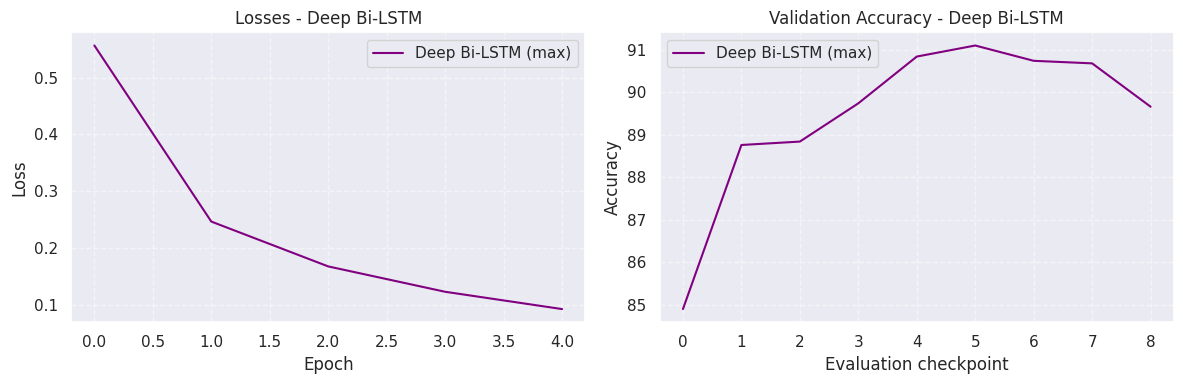

Лучшая accuracy для подхода Deep Bi-LSTM (max): 91.10%


In [59]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(np.arange(len(deep_losses)), deep_losses, color='purple', label='Deep Bi-LSTM (max)')
plt.title('Losses - Deep Bi-LSTM')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1, 2, 2)
acc_vals = deep_acc[1:] if len(deep_acc) > 1 else deep_acc
plt.plot(np.arange(len(acc_vals)), [a * 100 for a in acc_vals], color='purple', label='Deep Bi-LSTM (max)')
plt.title('Validation Accuracy - Deep Bi-LSTM')
plt.xlabel('Evaluation checkpoint')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

if deep_acc:
    print(f"Лучшая accuracy для подхода Deep Bi-LSTM (max): {(max(deep_acc) * 100):.2f}%")

### Сводное сравнение всех моделей и итоговый отчёт

Ниже строятся сравнительные графики функции потерь (Loss) и валидационной точности (Accuracy) для всех проведённых экспериментов, а также вычисляется финальный `score` лучшей модели.

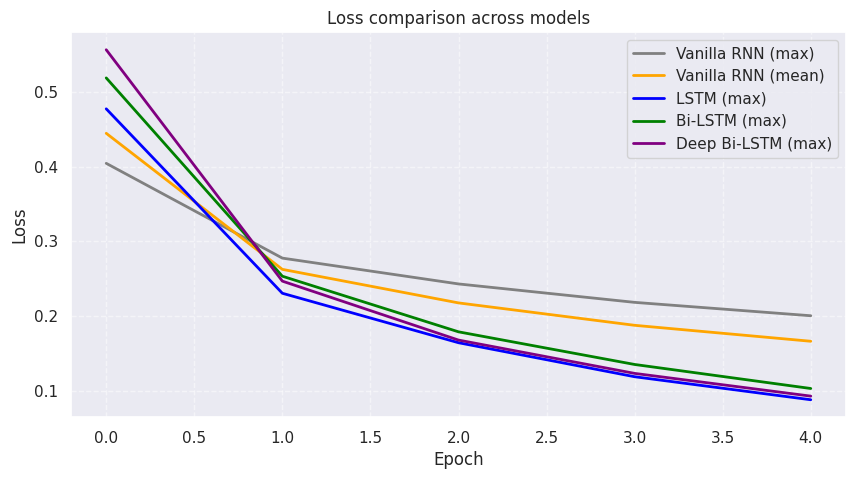

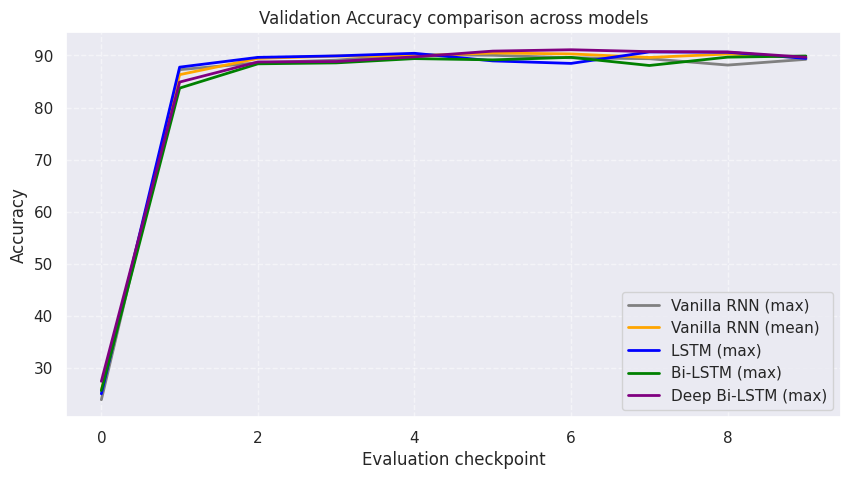

Модель                     Лучшая валидационная Accuracy 
Vanilla RNN (max)          90.18%
Vanilla RNN (mean)         90.48%
LSTM (max)                 90.68%
Bi-LSTM (max)              89.90%
Deep Bi-LSTM (max)         91.10%
лучшая модель: Deep Bi-LSTM (max) с результатом 91.10%


In [60]:
all_experiments = {
    'Vanilla RNN (max)': (losses_type.get('max', []), acc_type.get('max', []), model),
    'Vanilla RNN (mean)': (losses_type.get('mean', []), acc_type.get('mean', []), model),
    'LSTM (max)': (lstm_losses, lstm_acc, model_lstm),
    'Bi-LSTM (max)': (bilstm_losses, bilstm_acc, model_bilstm),
    'Deep Bi-LSTM (max)': (deep_losses, deep_acc, model_deep),
}

# 1. График Losses
plt.figure(figsize=(10, 5))
colors = ['gray', 'orange', 'blue', 'green', 'purple']
for (name, (losses, _, _)), color in zip(all_experiments.items(), colors):
    if losses:
        plt.plot(np.arange(len(losses)), losses, label=name, color=color, linewidth=2)
plt.title('Loss comparison across models')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

# 2. График Accuracy на валидации
plt.figure(figsize=(10, 5))
for (name, (_, acc, _)), color in zip(all_experiments.items(), colors):
    if acc:
        plt.plot(np.arange(len(acc)), [x * 100 for x in acc], label=name, color=color, linewidth=2)
plt.title('Validation Accuracy comparison across models')
plt.xlabel('Evaluation checkpoint')
plt.ylabel('Accuracy')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

# 3. Итоговая таблица результатов
print(f"{'Модель':<25}  {'Лучшая валидационная Accuracy':<30}")
best_overall_acc = 0.0
best_model_name = ""

for name, (_, acc, _) in all_experiments.items():
    if acc:
        max_a = max(acc) * 100
        if max_a > best_overall_acc:
            best_overall_acc = max_a
            best_model_name = name
        print(f"{name:<25}  {max_a:.2f}%")

print(f"лучшая модель: {best_model_name} с результатом {best_overall_acc:.2f}%")

В ходе работы были обучены и сопоставлены пять моделей: Vanilla RNN max (90.18%), Vanilla RNN mean (90.48%), LSTM max (90.68%), Bi-LSTM max (89.90%) и Deep Bi-LSTM max (91.10%).

Первый важный вывод нужно сделать следующий: результат различается от запуска к запуску. Один раз Deep Bi-LSTM может выдать 90.5%, в другой же раз 92%. То есть модели сильно зависят от начальных условий, начиная с инициализации весов и заканчивая подбором батчей.

Кроме того, можно было заметить, что в экспериментах в качестве агрегации использовался max pooling. В задаче тематической классификации новостей категория обычно определяется конкретными ключевыми словами, и max pooling позволяет выделить самые яркие признаки этих слов независимо от длины текста, в то время как mean pooling размывает ключевые сигналы среди нейтральных и служебных слов.

Переход от обычной RNN к LSTM улучшил качество на 0.5%, так как состояние ячейки и механизм гейтов решили проблему затухания градиентов на длинных последовательностях. Добавление двунаправленности в однослойную LSTM снизило точность до 89.90% из-за того, что обратный слой сначала проходил через токены паддинга, создавая шум для max pooling, а также из-за удвоения числа параметров. При этом двухслойная Bi-LSTM с межслойным dropout 0.3 показала лучший результат среди всех моделей (91.10%), так как позволила извлекать признаки на разных уровнях абстракции без переобучения.

Все модели продемонстрировали устойчивую сходимость за 5 эпох без резких колебаний на графиках, при этом функция потерь у LSTM-моделей снижалась заметно плавнее по сравнению с базовой RNN.

Оптимальной моделью по итогам экспериментов стала Deep Bi-LSTM, показавшая наивысшую точность 91.10%. Это не наивысший балл, однако перезапускать несколько раз ради 1 балла и ждать обучения моделей не имею желания, смирился с этим.